### 1 – Mostre como está a distribuição de Veículos com base no Ano de Registro. Para isso crie um Plot com a Distribuição de Veículos com base no Ano de Registro

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sijovm/used-cars-data-from-ebay-kleinanzeigen")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\sijovm\used-cars-data-from-ebay-kleinanzeigen\versions\1


In [6]:
#Importando as bibliotecas
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib as mat
import matplotlib.pyplot as plt

In [19]:
#Criando o dataframe
cars = pd.read_csv('autos.csv',encoding="latin-1")
cars["vehicleType"] = cars["vehicleType"].fillna("Other")

print(cars.shape)
cars.head(-10)

(371528, 20)


,dateCrawled,name,seller,offerType,price,abtest,vehicleType,yearOfRegistration,gearbox,powerPS,model,kilometer,monthOfRegistration,fuelType,brand,notRepairedDamage,dateCreated,nrOfPictures,postalCode,lastSeen
0,2016-03-24 11:52:17,Golf_3_1.6,privat,Angebot,480,test,Other,1993,manuell,0,golf,150000,0,benzin,volkswagen,NaN,2016-03-24 00:00:00,0,70435,2016-04-07 03:16:57
1,2016-03-24 10:58:45,A5_Sportback_2.7_Tdi,privat,Angebot,18300,test,coupe,2011,manuell,190,NaN,125000,5,diesel,audi,ja,2016-03-24 00:00:00,0,66954,2016-04-07 01:46:50
2,2016-03-14 12:52:21,"Jeep_Grand_Cherokee_""Overland""",privat,Angebot,9800,test,suv,2004,automatik,163,grand,125000,8,diesel,jeep,NaN,2016-03-14 00:00:00,0,90480,2016-04-05 12:47:46
3,2016-03-17 16:54:04,GOLF_4_1_4__3TÜRER,privat,Angebot,1500,test,kleinwagen,2001,manuell,75,golf,150000,6,benzin,volkswagen,nein,2016-03-17 00:00:00,0,91074,2016-03-17 17:40:17
4,2016-03-31 17:25:20,Skoda_Fabia_1.4_TDI_PD_Classic,privat,Angebot,3600,test,kleinwagen,2008,manuell,69,fabia,90000,7,diesel,skoda,nein,2016-03-31 00:00:00,0,60437,2016-04-06 10:17:21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
371513,2016-03-21 15:36:22,Seat_Leon_1.9_TDI_4/5_Tueren,privat,Angebot,4400,control,limousine,2008,manuell,105,leon,150000,7,diesel,seat,nein,2016-03-21 00:00:00,0,45896,2016-04-06 15:45:01
371514,2016-04-04 11:45:16,Renault_1_4_ltr.16_V_Megane_Cabrio,privat,Angebot,999,control,cabrio,2000,manuell,95,megane,150000,4,benzin,renault,NaN,2016-04-04 00:00:00,0,88477,2016-04-06 12:44:52
371515,2016-03-09 11:36:55,Skoda_Fabia_Kombi_1.4,privat,Angebot,1690,test,kombi,2004,manuell,55,fabia,150000,4,benzin,skoda,NaN,2016-03-09 00:00:00,0,18246,2016-04-04 08:15:30
371516,2016-04-04 09:57:12,Volkswagen_Lupo_1.0,privat,Angebot,1490,control,kleinwagen,1998,manuell,50,lupo,150000,9,benzin,volkswagen,nein,2016-04-04 00:00:00,0,48653,2016-04-06 11:17:13


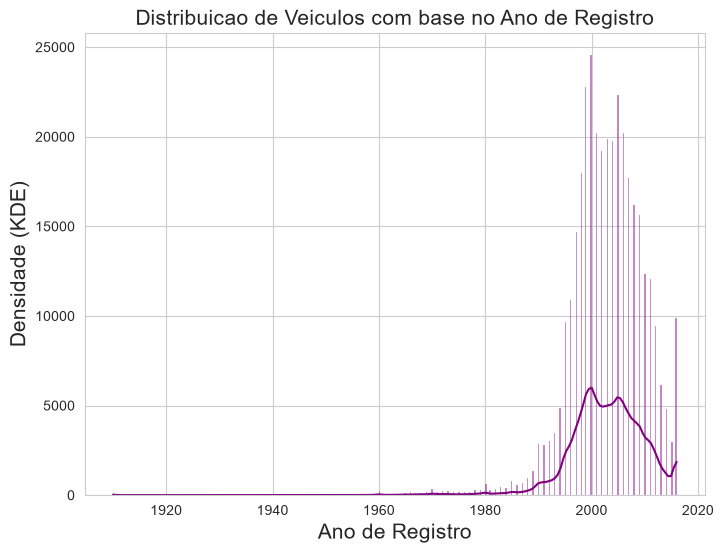

In [20]:
# Filtra apenas anos realistas para a visualização
carros_validos = cars[(cars["yearOfRegistration"] >= 1910) & (cars["yearOfRegistration"] <= 2016)]

fig, ax = plt.subplots(figsize=(8,6))
sb.histplot(carros_validos["yearOfRegistration"], color="purple", kde=True, ax=ax)
ax.set_title('Distribuicao de Veiculos com base no Ano de Registro', fontsize=15)
plt.ylabel("Densidade (KDE)", fontsize=15)
plt.xlabel("Ano de Registro", fontsize=15)
plt.show()

# 2 – Verifique a variação da faixa de preço pelo tipo de veículo, para isso crie um Boxplot para avaliar os outliers.

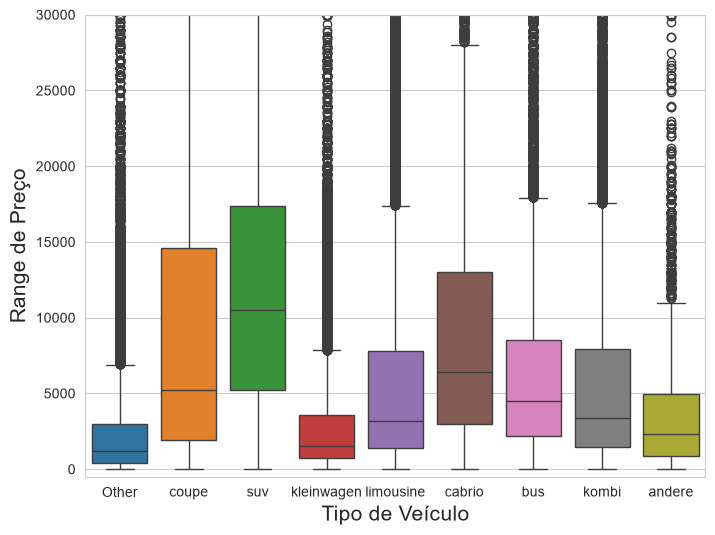

In [22]:
# Crie um Boxplot para avaliar os outliers
cars_limpo = cars[(cars["price"] >= 100) & (cars["price"] <= 100000)]

# 2. Configura o estilo
sb.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(8, 6))

# 3. Plota o Boxplot com paleta colorida
sb.boxplot(x="vehicleType", y="price", data=cars, palette="tab10", hue="vehicleType", legend=False)

# 4. Ajusta os limites do eixo Y para 0 a 30000 (igual ao slide)
ax.set_ylim(-500, 30000)

# 5. Títulos e rótulos
ax.xaxis.set_label_text("Tipo de Veículo", fontsize=15)
ax.yaxis.set_label_text("Range de Preço", fontsize=15)

plt.show()

# 3 – Realize uma contagem total de veículos à venda conforme o tipo de veículo. Para isso crie um Count Plot que mostre o número de veículos pertencentes a cada categoria.

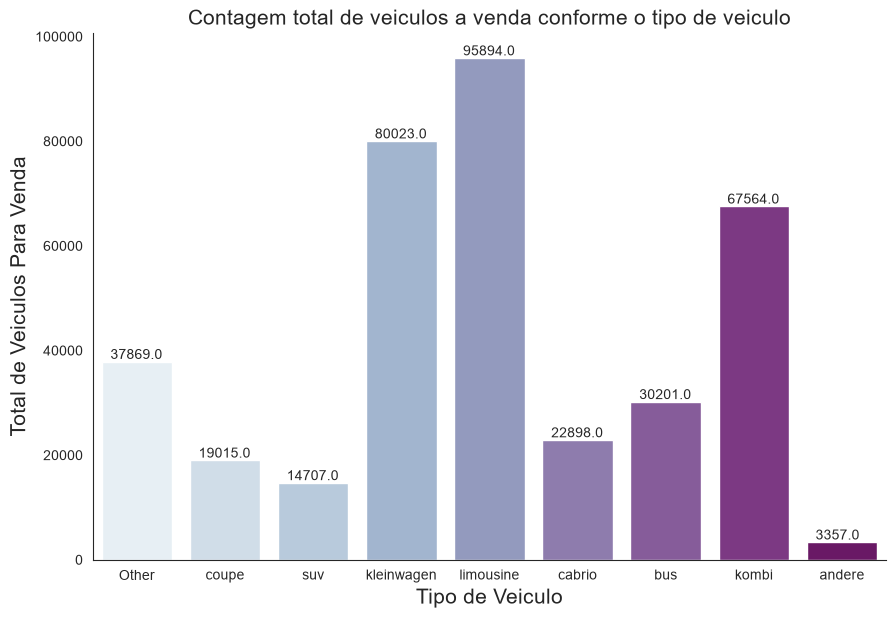

In [25]:
# Crie um Count Plot que mostre o numero de veiculos pertencentes a cada categoria
sb.set_style("white")

# Adicionado hue="vehicleType" e legend=False para adequar à nova versão do Seaborn
graf = sb.catplot(
    x="vehicleType", 
    data=cars, 
    kind="count", 
    palette="BuPu", 
    hue="vehicleType", 
    legend=False, 
    height=6, 
    aspect=1.5
)

graf.ax.xaxis.set_label_text("Tipo de Veiculo", fontsize=15)
graf.ax.yaxis.set_label_text("Total de Veiculos Para Venda", fontsize=15)
graf.ax.set_title("Contagem total de veiculos a venda conforme o tipo de veiculo", fontsize=15)

# Para mostrar as contagens na parte superior da barra
for p in graf.ax.patches:
    graf.ax.annotate((p.get_height()), (p.get_x() + 0.1, p.get_height() + 500))

plt.show()

# 4 – Realize uma contagem do número de veículos de cada marca e crie um um Plot que mostre esse número de veículos pertencentes a cada marca.

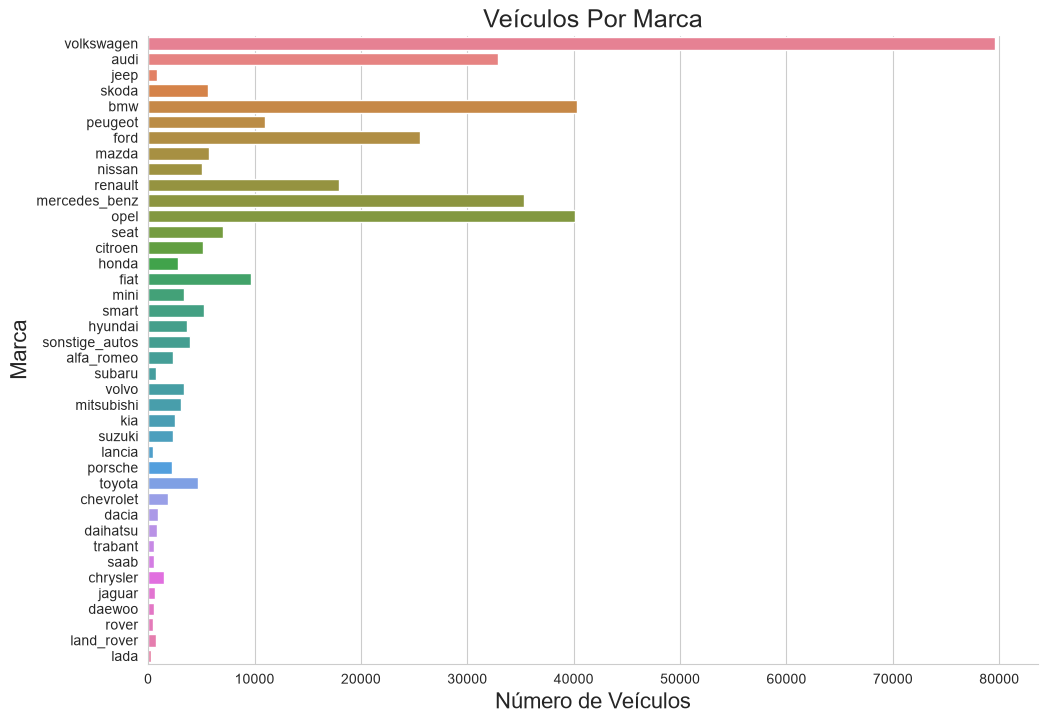

In [27]:
# Crie um Plot que mostre o numero de veiculos pertencentes a cada marca
sb.set_style("whitegrid")

graf = sb.catplot(
    y="brand", 
    data=cars, 
    kind="count", 
    palette="husl",       # Aplica a paleta colorida em degradê do slide
    hue="brand",          # Mapeia cada cor para uma marca
    legend=False,         # Impede a criação de uma legenda com 40 marcas
    height=7, 
    aspect=1.5
)

graf.ax.set_title("Veículos Por Marca", fontdict={'size': 18})
graf.ax.xaxis.set_label_text("Número de Veículos", fontdict={'size': 16})
graf.ax.yaxis.set_label_text("Marca", fontdict={'size': 16})

plt.show()

# 5 – Calcule o preço médio dos veículos com base no tipo de veículo, bem como no tipo de caixa de câmbio e crie um Plot com o Preço médio dos veículos com base no tipo de veículo, bem como no tipo de caixa de câmbio

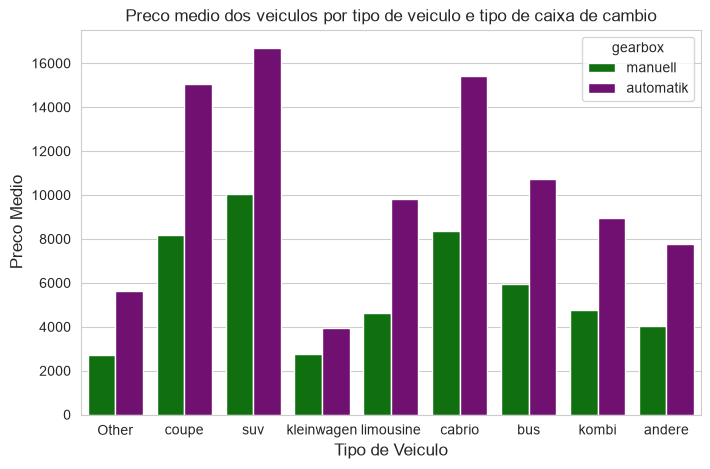

In [30]:
# Crie um Plot com o Preço médio dos veiculos
# com base no tipo de veiculo, bem como no tipo de caixa de câmbio
fig, ax = plt.subplots(figsize=(8, 5))

# 1. Definir apenas 2 cores (correspondentes às 2 opções de câmbio)
colors = ["green", "purple"]

# 2. Utilizar dados filtrados (ex: preços realistas até 100.000) e errorbar=None para desenhar de imediato
cars_validos = cars[(cars["price"] >= 100) & (cars["price"] <= 100000)]

sb.barplot(
    x="vehicleType", 
    y="price", 
    hue="gearbox", 
    palette=colors, 
    data=cars_validos,
    errorbar=None   # Acelera a renderização ao ignorar o bootstrapping pesado
)

ax.set_title("Preco medio dos veiculos por tipo de veiculo e tipo de caixa de cambio", fontdict={'size': 12})
ax.xaxis.set_label_text("Tipo de Veiculo", fontdict={'size': 12})
ax.yaxis.set_label_text("Preco Medio", fontdict={'size': 12})

plt.show()

# 6 – Crie um Barplot com o preço médio do veículo por tipo de veículo e tipo de vendedor.

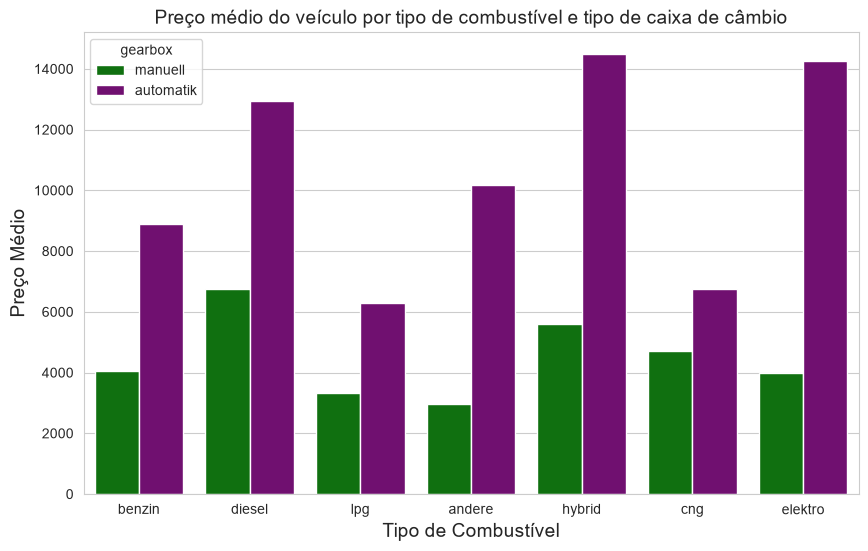

In [32]:
# Criar um BarPlot com o Preço médio do veículo por tipo de combustível e tipo de caixa de câmbio
fig, ax = plt.subplots(figsize=(10, 6))

# Apenas 2 cores necessárias para as 2 opções de câmbio (manuell / automatik)
colors = ["green", "purple"]

# Filtro para evitar a distorção dos preços extremos
cars_validos = cars[(cars["price"] >= 100) & (cars["price"] <= 100000)]

sb.barplot(
    x="fuelType", 
    y="price", 
    hue="gearbox", 
    palette=colors, 
    data=cars_validos,
    errorbar=None
)

ax.set_title("Preço médio do veículo por tipo de combustível e tipo de caixa de câmbio", fontsize=14)
ax.xaxis.set_label_text("Tipo de Combustível", fontsize=14)
ax.yaxis.set_label_text("Preço Médio", fontsize=14)

plt.show()

# 7 – Crie um Barplot com a Potência média de um veículo por tipo de veículo e tipo de caixa de câmbio

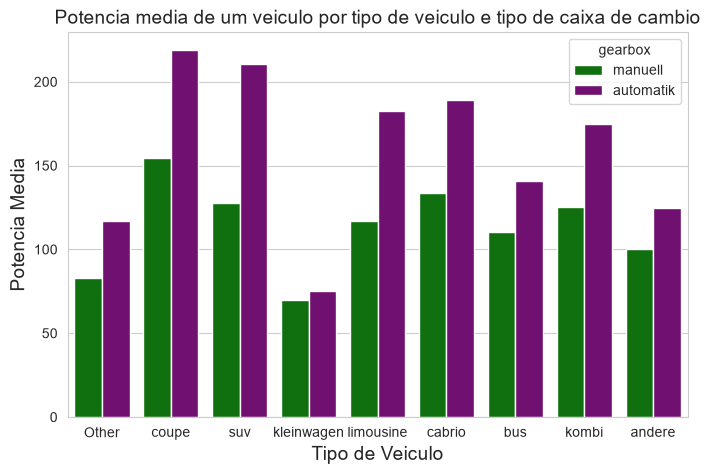

In [34]:
# Criar um Barplot com a Potencia media de um veiculo por tipo de veiculo e tipo de caixa de câmbio
fig, ax = plt.subplots(figsize=(8, 5))

# 2 cores correspondentes aos 2 tipos de caixa de velocidades
colors = ["green", "purple"]

# Corrigido: 'powerPS' com 'PS' em maiúsculas
sb.barplot(
    x="vehicleType", 
    y="powerPS", 
    hue="gearbox", 
    palette=colors, 
    data=cars,
    errorbar=None
)

ax.set_title("Potencia media de um veiculo por tipo de veiculo e tipo de caixa de cambio", fontsize=14)
ax.xaxis.set_label_text("Tipo de Veiculo", fontsize=14)
ax.yaxis.set_label_text("Potencia Media", fontsize=14)

plt.show()

# 8 – Calcule e mostre uma tabela com a média de preço por marca e por veículo. Dica: crie dois laços for.

In [39]:
# Calculando a média de preço por marca e por veículo
mv_lista = []

for b in list(cars["brand"].unique()):
    for v in list(cars["vehicleType"].unique()):
        z = cars[(cars["brand"] == b) & (cars["vehicleType"] == v)]["price"].mean()
        # Coleta os dados em formato de DataFrame dentro do loop
        mv_lista.append(pd.DataFrame({'brand': [b], 'vehicleType': [v], 'avgPrice': [z]}))

# Junta todos os blocos de uma vez só
mv = pd.concat(mv_lista, ignore_index=True)

# Trata valores nulos (NaN) e converte para número inteiro
mv["avgPrice"] = mv["avgPrice"].fillna(0).astype(int)

# Visualiza as primeiras linhas
mv.head(10)

,brand,vehicleType,avgPrice
0,volkswagen,Other,42240
1,volkswagen,coupe,14854
2,volkswagen,suv,15898
3,volkswagen,kleinwagen,9261
4,volkswagen,limousine,10849
5,volkswagen,cabrio,6548
6,volkswagen,bus,9237
7,volkswagen,kombi,5757
8,volkswagen,andere,132901
9,audi,Other,9622


# 9 – Crie um Heatmap com Preço médio de um veículo por marca, bem como tipo de veículo.

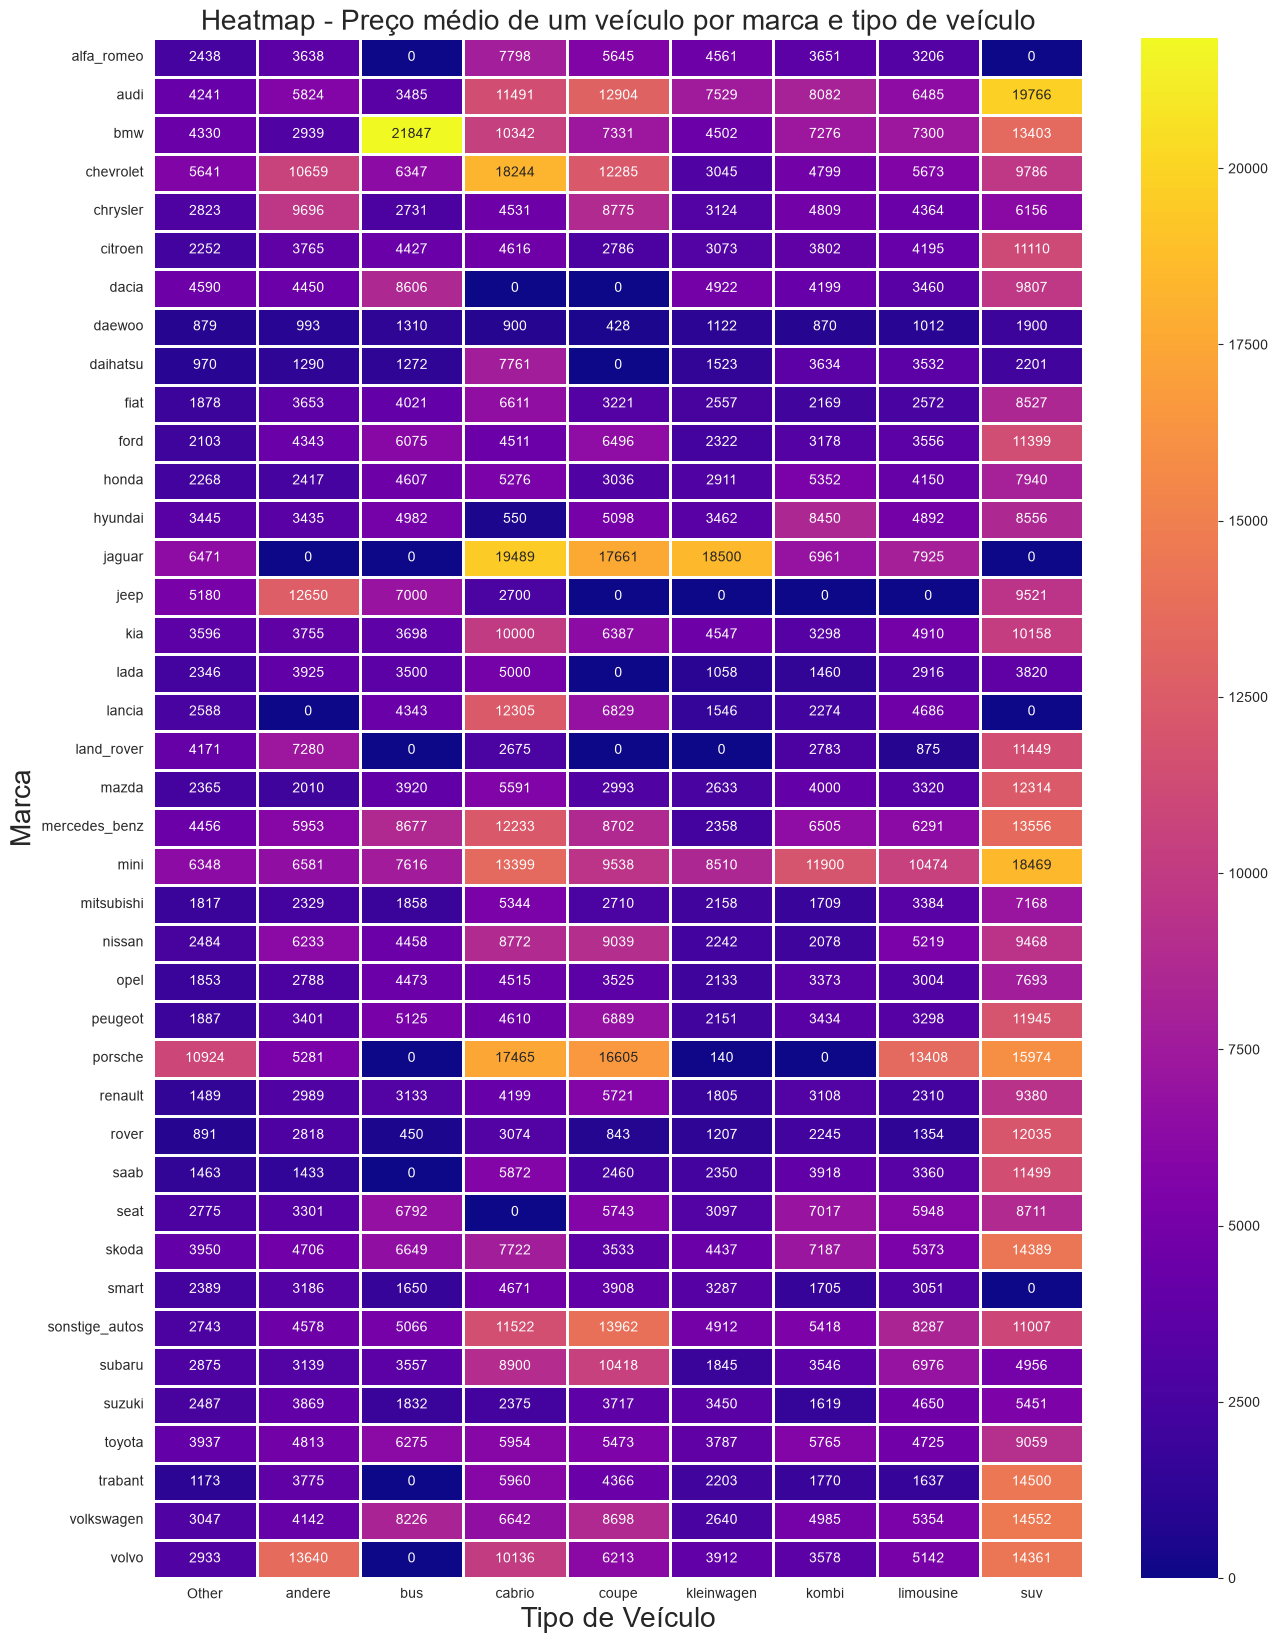

In [44]:
# 1. Filtra na mesma faixa usada no boxplot da aula (até 30.000)
cars_limpo = cars[(cars["price"] >= 100) & (cars["price"] <= 30000)]

# 2. Recalcula as médias
mv = cars_limpo.groupby(["brand", "vehicleType"])["price"].mean().reset_index()
mv.rename(columns={"price": "avgPrice"}, inplace=True)
mv["avgPrice"] = mv["avgPrice"].fillna(0).astype(int)

# 3. Gera o pivô e o heatmap
tri = mv.pivot(index="brand", columns="vehicleType", values="avgPrice")
tri = tri.fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(15, 20))
sb.heatmap(tri, linewidths=1, cmap="plasma", annot=True, ax=ax, fmt="d")

ax.set_title("Heatmap - Preço médio de um veículo por marca e tipo de veículo", fontsize=20)
ax.xaxis.set_label_text("Tipo de Veículo", fontsize=20)
ax.yaxis.set_label_text("Marca", fontsize=20)

plt.show()